# 5주차 — SigLIP 2로 만드는 텍스트 → 이미지 검색
**임지민 · DRAG**

사진 300장을 숫자 벡터로 바꿔 FAISS에 저장하고, 영어·한국어 문장으로 검색합니다.

기반: [smol-vision / Image_Search_with_MetaCLIP2.ipynb](https://github.com/merveenoyan/smol-vision/blob/main/Image_Search_with_MetaCLIP2.ipynb).
원본의 **이미지 인코딩 → 정규화 → FAISS → 텍스트 검색 → 이미지 출력** 흐름을 따릅니다.
MetaCLIP2 대신 다국어 **google/siglip2-base-patch16-224**, 음식 사진 대신 캡션이 있는 Flickr8k, GPU 전용 FAISS 대신 `faiss-cpu`를 사용합니다.

SigLIP 2는 SigLIP 계열의 후속 다국어 모델입니다. 유료 API·Ollama·모델 학습은 사용하지 않습니다.
설치: 터미널에서 `python -m pip install -r requirements.txt`. 이후 이 노트북의 커널을 설치한 환경으로 선택하고 **모두 실행**하세요.


## 1. 환경과 설정
CPU로 실행합니다. 배치 8장, seed 42로 고정하여 다른 컴퓨터에서도 같은 자료를 선택합니다.

In [1]:
import csv
import hashlib
import io
import json
import os
from pathlib import Path
import platform
import random
import textwrap
import time
from concurrent.futures import ThreadPoolExecutor
from urllib.request import Request, urlopen

import faiss
import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFont, ImageOps
from transformers import AutoModel, AutoProcessor

BASE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
DATA = BASE / 'data'
RESULTS = BASE / 'results'
MODEL_ID = 'google/siglip2-base-patch16-224'
DATASET = 'intro/flickr8k'
REVISION = 'c7a02cb487da0eca729e133194b0f842cb578c08'
SEED = 42
N_IMAGES = 300
BATCH_SIZE = 8
DEVICE = 'cpu'  # Windows/Mac 모두 가능한 기본값. CUDA는 별도 설정 가능.
torch.set_num_threads(min(4, os.cpu_count() or 1))

C:\Users\celin\Documents\ChatGPT\RAG 스터디\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. 사진과 캡션 준비
Flickr8k test 1,000장 중 300장을 고정 추출합니다. 전체 데이터셋 대신 필요한 파일만 다운로드합니다. 사진마다 원래 영어 캡션 5개를 보존합니다.

In [2]:
def download(url, destination):
    if destination.exists():
        return
    for attempt in range(3):
        try:
            with urlopen(Request(url, headers={'User-Agent': 'DRAG-week5-study/1.0'}), timeout=45) as response:
                content = response.read()
            temporary = destination.with_suffix(destination.suffix + '.tmp')
            temporary.write_bytes(content)
            temporary.replace(destination)
            return
        except Exception:
            if attempt == 2:
                raise
            time.sleep(attempt + 1)


def prepare_dataset():
    DATA.mkdir(parents=True, exist_ok=True)
    RESULTS.mkdir(parents=True, exist_ok=True)
    root = f'https://huggingface.co/datasets/{DATASET}/resolve/{REVISION}/test/'
    download(root + 'metadata.csv', DATA / 'metadata.csv')
    with (DATA / 'metadata.csv').open(encoding='utf-8', newline='') as handle:
        all_rows = sorted(csv.DictReader(handle), key=lambda row: row['file_name'])
    selected = random.Random(SEED).sample(all_rows, N_IMAGES)
    records = []
    for row in selected:
        name = row['file_name']
        if Path(name).name != name:
            raise ValueError('Invalid dataset filename')
        records.append({'id': name, 'path': 'data/' + name,
                        'captions': [row[f'caption_{i}'] for i in range(5)],
                        'source': root + name})
    with ThreadPoolExecutor(max_workers=4) as pool:
        list(pool.map(lambda r: download(r['source'], BASE / r['path']), records))
    for record in records:
        with Image.open(BASE / record['path']) as image:
            image.verify()
        record['sha256'] = hashlib.sha256((BASE / record['path']).read_bytes()).hexdigest()
    assert len({r['id'] for r in records}) == N_IMAGES
    (RESULTS / 'manifest.json').write_text(json.dumps(records, ensure_ascii=False, indent=2), encoding='utf-8')
    print(f'Dataset: {len(records)} images / {len(records)*5} captions / seed={SEED}', flush=True)
    return records

## 3. SigLIP 이미지·텍스트 임베딩
이미지와 문장을 같은 벡터 공간으로 옮깁니다. 캡션을 이미지 대신 임베딩하지 않습니다. 두 벡터 모두 길이 1로 정규화합니다.

In [3]:
def load_model():
    # 기존 프로젝트 캐시가 있으면 재사용. 다른 컴퓨터에서는 자동 다운로드.
    from huggingface_hub import snapshot_download
    cache = BASE.parents[1] / '.local-ai' / 'siglip'
    source = MODEL_ID
    if cache.exists():
        try:
            source = snapshot_download(MODEL_ID, cache_dir=str(cache), local_files_only=True)
        except OSError:
            pass
    processor = AutoProcessor.from_pretrained(source, trust_remote_code=False)
    model = AutoModel.from_pretrained(source, trust_remote_code=False, use_safetensors=True).to(DEVICE).eval()
    return processor, model


def normalize(features):
    # FAISS는 contiguous float32 배열을 사용한다.
    array = np.ascontiguousarray(features.detach().cpu().float().numpy(), dtype=np.float32)
    faiss.normalize_L2(array)
    return array


def embed_images(records, processor, model):
    batches = []
    with torch.inference_mode():
        for start in range(0, len(records), BATCH_SIZE):
            images = []
            for record in records[start:start+BATCH_SIZE]:
                with Image.open(BASE / record['path']) as image:
                    images.append(ImageOps.exif_transpose(image).convert('RGB'))
            inputs = processor(images=images, return_tensors='pt').to(DEVICE)
            batches.append(normalize(model.get_image_features(**inputs)))
            print(f'Image embeddings {min(start+BATCH_SIZE,len(records))}/{len(records)}', flush=True)
    return np.concatenate(batches)


def embed_texts(texts, processor, model):
    batches = []
    with torch.inference_mode():
        for start in range(0, len(texts), 16):
            inputs = processor(text=texts[start:start+16], padding='max_length',
                               truncation=True, max_length=64, return_tensors='pt').to(DEVICE)
            batches.append(normalize(model.get_text_features(**inputs)))
    return np.concatenate(batches)

## 4. FAISS 저장과 재로딩
원본의 1,280차원 하드코딩을 실제 출력 차원으로 바꿉니다. IndexFlatIP는 정규화 벡터의 코사인 유사도로 검색하며 큰 점수가 더 가깝습니다. 원본 IndexFlatL2는 작은 거리가 더 가깝지만, 정규화 벡터에서는 같은 순위를 줍니다.

In [4]:
def build_index(vectors):
    assert vectors.dtype == np.float32 and np.isfinite(vectors).all()
    assert np.allclose(np.linalg.norm(vectors, axis=1), 1, atol=1e-5)
    # 정규화된 벡터의 내적은 코사인 유사도. 높을수록 유사하다.
    index = faiss.IndexFlatIP(vectors.shape[1])
    index.add(vectors)
    # Windows 한글 경로 호환: FAISS 직접 경로 I/O 대신 serialize 사용.
    (RESULTS / 'images.faiss').write_bytes(faiss.serialize_index(index).tobytes())
    restored = faiss.deserialize_index(np.frombuffer((RESULTS / 'images.faiss').read_bytes(), dtype=np.uint8).copy())
    assert restored.ntotal == len(vectors)
    scores, ids = restored.search(vectors[:5], 1)
    assert np.array_equal(ids[:,0], np.arange(5))
    assert np.allclose(scores, 1, atol=1e-5)
    print(f'FAISS saved/reloaded: {restored.ntotal} vectors, dimension={restored.d}', flush=True)
    return restored


def search(query, index, records, processor, model, k=5):
    if not query.strip() or not 1 <= k <= len(records):
        raise ValueError('Query and k must be valid')
    vector = embed_texts([query], processor, model)
    scores, ids = index.search(vector, k)
    return [{'rank': rank+1, 'score': float(score), **records[int(i)]}
            for rank, (score, i) in enumerate(zip(scores[0], ids[0]))]

## 5. 검색 결과 캡처 함수
실제 검색 순위·유사도·원본 캡션을 PNG로 저장합니다. 캡션은 결과를 확인하기 위한 설명일 뿐 검색 인덱스에는 들어가지 않습니다.

In [5]:
def font(size):
    candidates = [os.environ.get('KOREAN_FONT', ''), 'C:/Windows/Fonts/malgun.ttf',
                  '/System/Library/Fonts/AppleSDGothicNeo.ttc',
                  '/usr/share/fonts/truetype/nanum/NanumGothic.ttf']
    for candidate in candidates:
        if candidate and Path(candidate).is_file():
            return ImageFont.truetype(candidate, size)
    return ImageFont.truetype('DejaVuSans.ttf', size)


def render_results(query, hits, filename, language):
    # 실제 FAISS 반환 결과를 캡처용 이미지로 저장한다. 순위 수동 교체 없음.
    canvas = Image.new('RGB', (1800, 790), '#f4f6fa')
    draw = ImageDraw.Draw(canvas)
    draw.text((45,25), f'SigLIP 2 + FAISS | {language}', font=font(34), fill='#19334b')
    draw.text((45,85), query, font=font(29), fill='#202934')
    draw.text((45,135), f'Flickr8k: 300 images | Top {len(hits)} | Cosine similarity (not probability)', font=font(20), fill='#596574')
    for col, hit in enumerate(hits):
        x = 35 + col * 353
        draw.rounded_rectangle((x,190,x+335,730),radius=16,fill='white')
        with Image.open(BASE / hit['path']) as original:
            thumbnail = ImageOps.contain(original.convert('RGB'), (315,280))
        canvas.paste(thumbnail,(x+10+(315-thumbnail.width)//2,210+(280-thumbnail.height)//2))
        draw.text((x+15,515),f"#{hit['rank']}   {hit['score']:.4f}",font=font(26),fill='#19334b')
        for line_no, line in enumerate(textwrap.wrap(hit['captions'][0],width=29)[:6]):
            draw.text((x+15,562+line_no*24),line,font=font(18),fill='#303b49')
    draw.text((45,751),'Captions are shown for inspection only; the index contains image embeddings.',font=font(19),fill='#596574')
    canvas.save(RESULTS / filename)
    return canvas

## 6. Recall@K 평가 함수
정답 사진이 Top K 안에 들어간 캡션 질의 수 / 전체 질의 수입니다. 300장의 영어 캡션을 모두 사용해 총 1,500번 평가합니다. 300장 후보 안에서의 결과이므로 전체 Flickr8k 성능과 직접 비교하면 안 됩니다.

In [6]:
def evaluate(index, records, processor, model):
    captions = [caption for r in records for caption in r['captions']]
    truth = np.repeat(np.arange(len(records)),5)
    vectors = embed_texts(captions,processor,model)
    scores, found = index.search(vectors,10)
    metrics = {f'Recall@{k}': float(np.mean(np.any(found[:,:k] == truth[:,None],axis=1))) for k in [1,5,10]}
    # 모든 300장 x 영어 캡션 5개 = 1,500개 질의. 부분집합 내 retrieval 평가.
    details = [{'image_id': records[int(t)]['id'], 'caption': c,
                'top10_ids': [records[int(j)]['id'] for j in indices],
                'correct_rank': next((rank+1 for rank,j in enumerate(indices) if j==t),None)}
               for t,c,indices in zip(truth,captions,found)]
    (RESULTS/'evaluation_details.json').write_text(json.dumps(details,ensure_ascii=False,indent=2),encoding='utf-8')
    report = {'dataset':DATASET,'revision':REVISION,'split':'test','seed':SEED,'images':len(records),
              'queries':len(captions),'model':MODEL_ID,'device':DEVICE,'dimension':index.d,
              'index':'IndexFlatIP (L2-normalized)','metrics':metrics,
              'scope':'English captions, 300-image candidate set. No training/fine-tuning. Not a full Flickr8k benchmark.',
              'versions':{'python':platform.python_version(),'torch':torch.__version__,'faiss':faiss.__version__}}
    (RESULTS/'metrics.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
    print(json.dumps(report,indent=2),flush=True)
    return report

## 7. 준비부터 저장까지 실제 실행
처음에는 모델·사진 다운로드가 필요합니다. 재실행 시 사진은 재사용하지만 이미지 임베딩은 다시 계산합니다.

In [7]:
records = prepare_dataset()
processor, model = load_model()
vectors = embed_images(records, processor, model)
index = build_index(vectors)

Dataset: 300 images / 1500 captions / seed=42


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Image embeddings 8/300


Image embeddings 16/300


Image embeddings 24/300


...

Image embeddings 280/300


Image embeddings 288/300


Image embeddings 296/300


Image embeddings 300/300


FAISS saved/reloaded: 300 vectors, dimension=768


## 8. 같은 의미의 영어·한국어 질의
미리 정한 두 쌍의 질문을 그대로 실행합니다. 순위가 언어마다 달라질 수 있습니다.

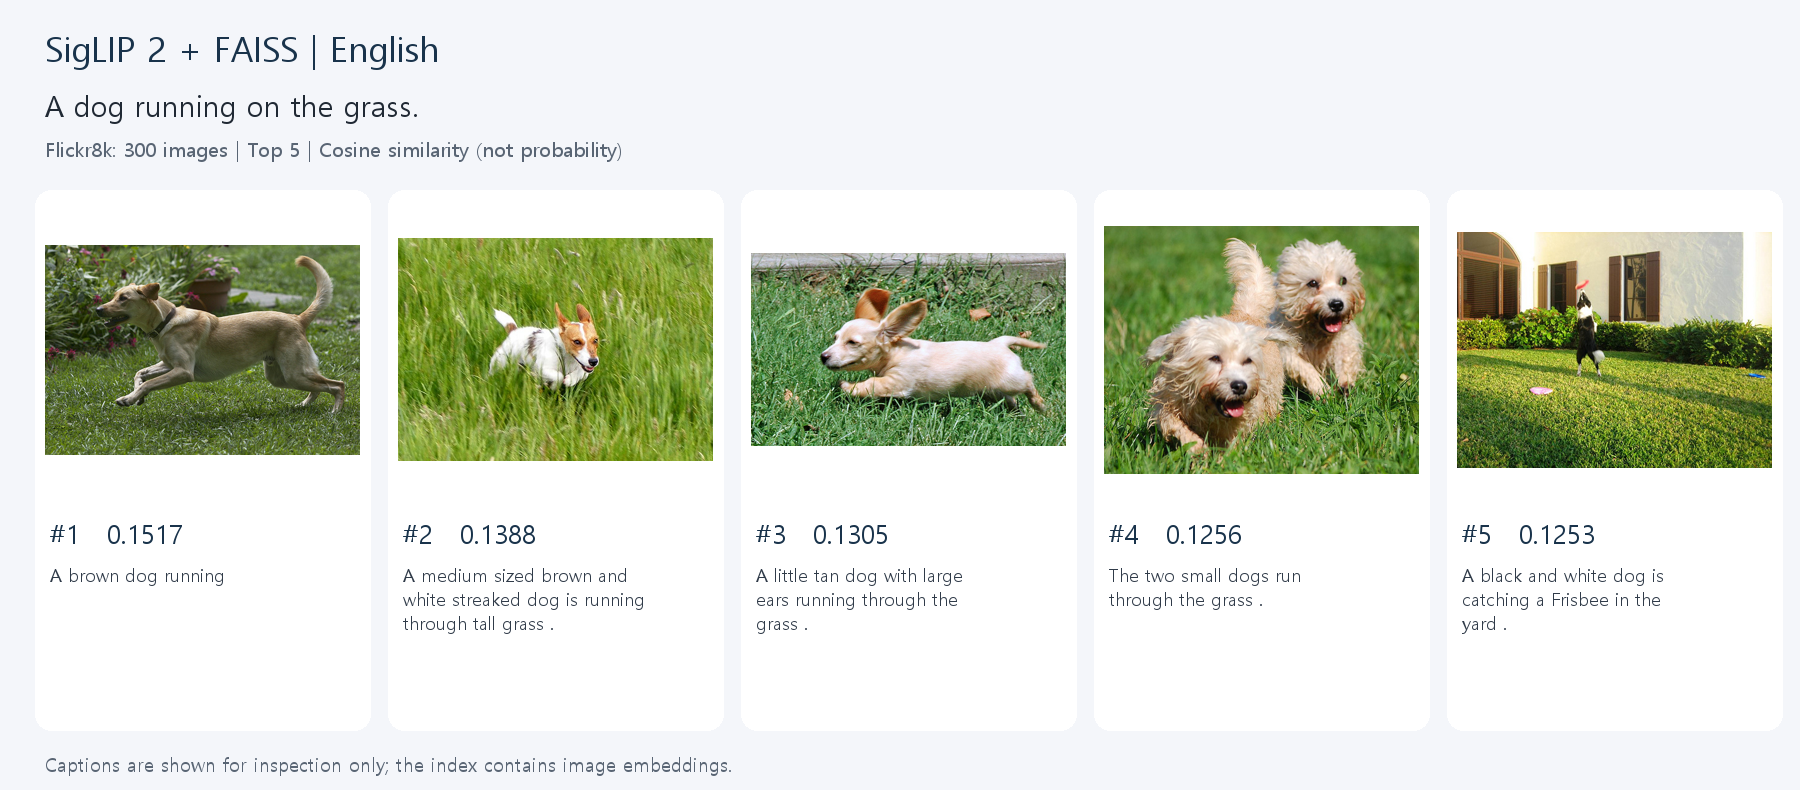

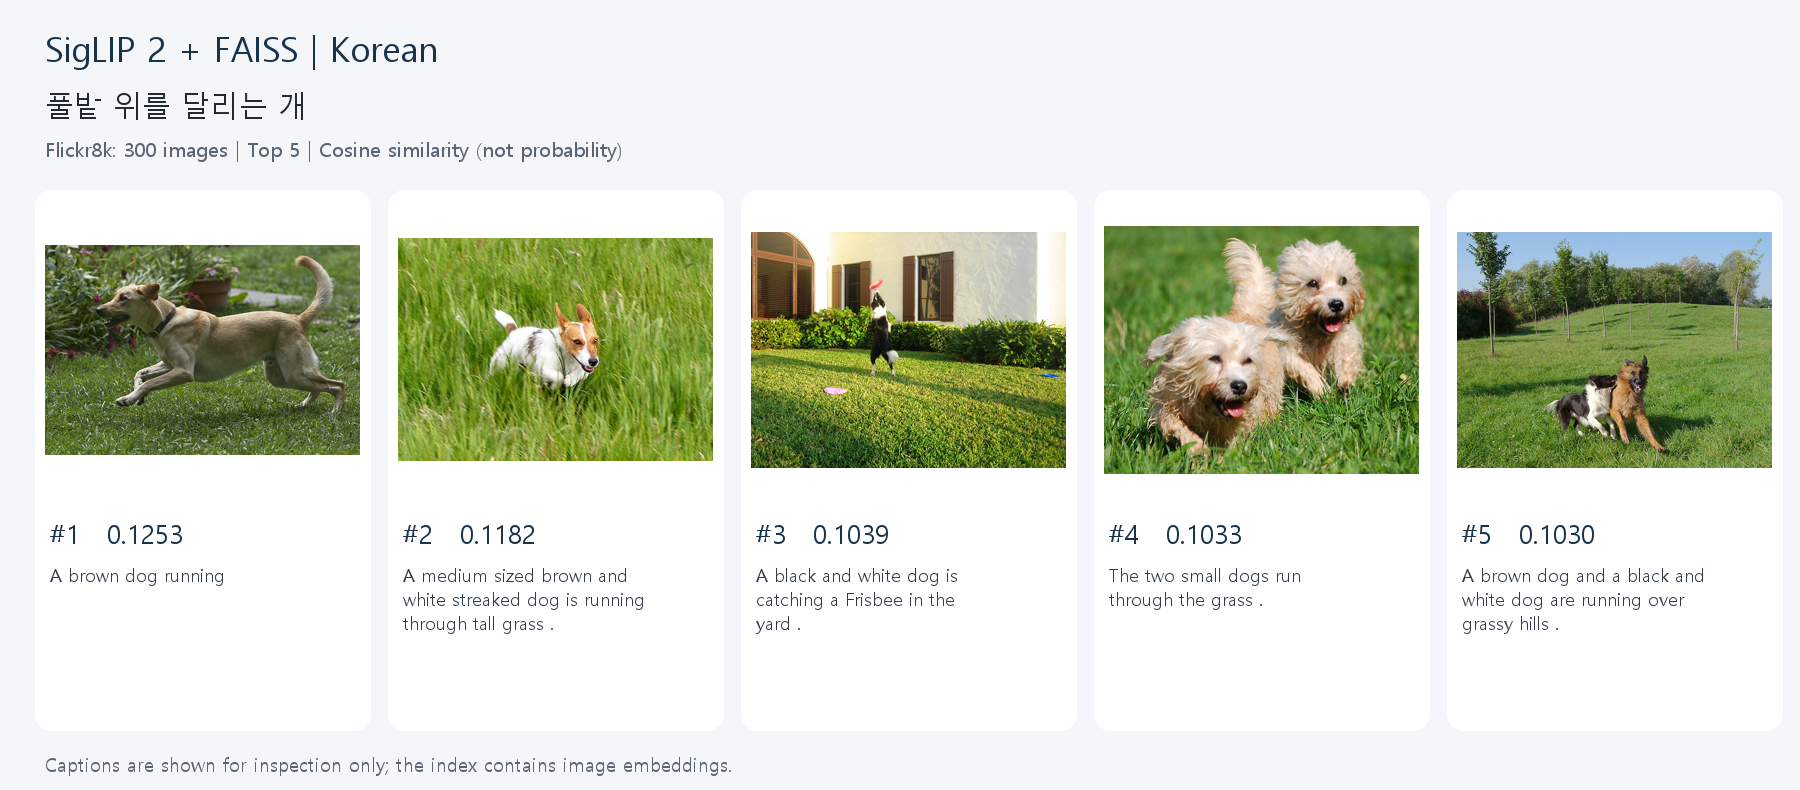

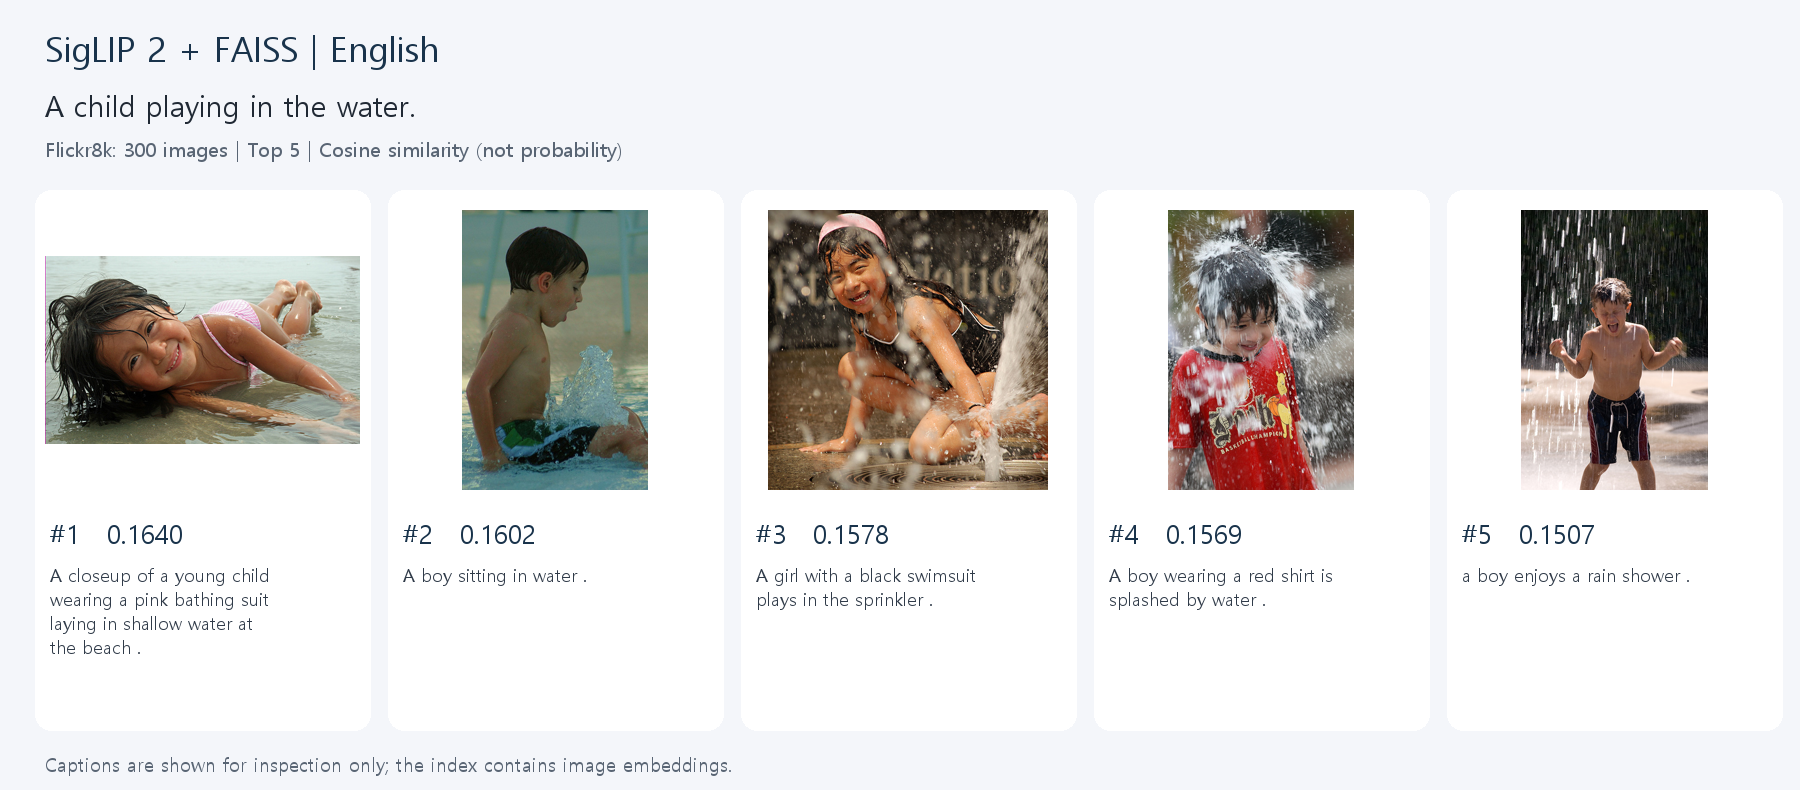

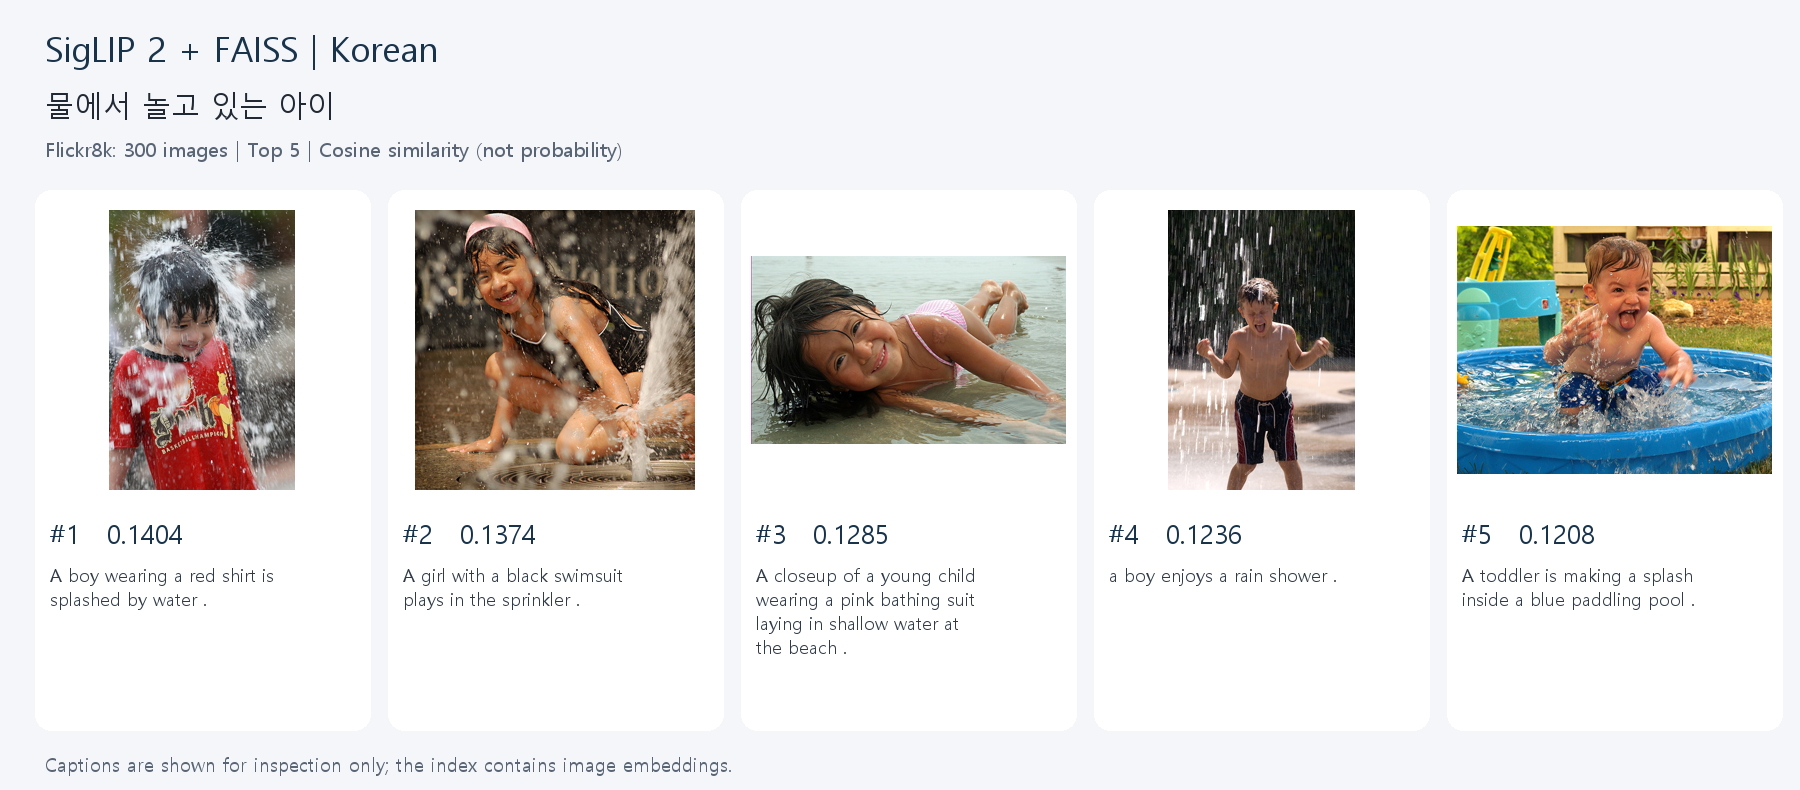

15943

In [8]:
from IPython.display import display
query_pairs = [
    ('A dog running on the grass.', '풀밭 위를 달리는 개'),
    ('A child playing in the water.', '물에서 놀고 있는 아이'),
]
search_log = []
for pair_id, pair in enumerate(query_pairs, 1):
    for lang, query in zip(['English', 'Korean'], pair):
        hits = search(query, index, records, processor, model, k=5)
        filename = f'query_{pair_id}_{lang.lower()}.png'
        display(render_results(query, hits, filename, lang))
        search_log.append({'query': query, 'language': lang, 'results': hits})
(RESULTS/'search_results.json').write_text(json.dumps(search_log,ensure_ascii=False,indent=2),encoding='utf-8')

## 9. 선택 과제 — Recall@1, @5, @10
한국어는 정성 비교용입니다. 아래 정량 평가는 원본 영어 캡션만 사용합니다. 모델 사전학습 데이터와의 중복은 확인할 수 없으며, 별도 학습 없이 검색만 수행했습니다.

In [9]:
report = evaluate(index, records, processor, model)

{
  "dataset": "intro/flickr8k",
  "revision": "c7a02cb487da0eca729e133194b0f842cb578c08",
  "split": "test",
  "seed": 42,
  "images": 300,
  "queries": 1500,
  "model": "google/siglip2-base-patch16-224",
  "device": "cpu",
  "dimension": 768,
  "index": "IndexFlatIP (L2-normalized)",
  "metrics": {
    "Recall@1": 0.8553333333333333,
    "Recall@5": 0.9826666666666667,
    "Recall@10": 0.9933333333333333
  },
  "scope": "English captions, 300-image candidate set. No training/fine-tuning. Not a full Flickr8k benchmark.",
  "versions": {
    "python": "3.12.14",
    "torch": "2.14.1+cpu",
    "faiss": "1.15.1"
  }
}


## 10. 결과 해석 및 참고
- 높은 코사인 유사도는 상대적으로 관련 있다는 뜻이며 정답 확률이 아닙니다.
- 항상 K장을 반환하므로, 관련 없는 결과도 하위 순위에 포함될 수 있습니다.
- `results/manifest.json`의 순서가 FAISS 벡터 ID와 일치합니다. 순서를 바꾸면 사진과 벡터가 어긋납니다.
- `results/images.faiss`에는 이미지 벡터만 있으며 사진 원본은 `data/`에 있습니다.
- 막힌 점과 해결은 `ISSUES.md`, 실행 안내는 `README.md`에 기록합니다.

자료: [SigLIP 2 모델 카드](https://huggingface.co/google/siglip2-base-patch16-224), [Flickr8k 패키지](https://huggingface.co/datasets/intro/flickr8k), [FAISS](https://github.com/facebookresearch/faiss/wiki/Getting-started).
원본 사진은 다운로드하여 로컬 실습에 사용합니다. 결과 공유 시 데이터셋과 원본 사진의 이용 조건을 확인하세요.
